# Notebook 00: Agricultural Cost of Cultivation (COC) — Dataset Audit & EDA
**Project:** IT4010 Intelligent Decision Support System for Agricultural Cost Prediction  
**Objective:** Comprehensive exploratory data analysis, season-ordered time index verification, and macroeconomic regime analysis across 2014–2025.


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Add src to path
src_dir = Path.cwd().parent / "src"
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

from data import load_model_data, get_feature_and_target_columns

df = load_model_data()
print(f"Total modeling records: {len(df)}")
print(f"Unique crops ({df['Crop'].nunique()}): {sorted(df['Crop'].unique())}")
print(f"Unique districts ({df['District'].nunique()}): {sorted(df['District'].unique())}")
print(f"Unique series: {df['series_key'].nunique()}")
df.head()


Total modeling records: 641
Unique crops (23): ['Big Onion', 'Bitter Gourd', 'Black Gram', 'Brinjal', 'Cabbage', 'Capsicum', 'Carrot', 'Cowpea', 'Gingelly', 'Green Chilli', 'Green Gram', 'Groundnut', 'Kurakkan', 'Maize', 'Manioc', 'Paddy', 'Pole Bean', 'Potato', 'Pumpkin', 'Red Onion', 'Soybean', 'Sweet Potato', 'Tomato']
Unique districts (25): ['Ampara', 'Ampara (East)', 'Ampara (West)', 'Anuradhapura', 'Badulla', 'Batticaloa', 'Gampaha', 'Hambantota', 'Jaffna', 'Kalutara', 'Kandy', 'Kurunegala', 'Mahaweli System B', 'Mahaweli System C', 'Mahaweli System H', 'Mannar', 'Matale', 'Monaragala', 'Nuwara Eliya', 'Polonnaruwa', 'Puttalam', 'Trincomalee', 'Udawalawa', 'Vavuniya', 'Whole Island']
Unique series: 95


,Season,Year_Start,Year_End,Year_Range,Crop,District,Irrigation_Type,Field_Size_Basis,Labour_Cost,Machinery_Cost,...,Cost_Pct_Change_From_Prev_Season,Fertilizer_Cost_Pct_of_Total,Labour_Cost_Pct_of_Total,Machinery_Cost_Pct_of_Total,Crop_Sample_Size_Category,season_order_key,calendar_date,series_key,economic_regime,row_id
0,Maha,2015,2016,2015-16,Big Onion,Matale,Irrigated,Per Acre,119771.00,26997.0,...,NaN,0.303182,0.568643,0.128175,Medium,4031,2015-10-01,Big Onion | Matale | Irrigated,Stable,0
1,Yala,2018,2018,2018,Big Onion,Matale,Irrigated,Per Acre,147374.00,29458.0,...,8.553075,0.226595,0.644565,0.128840,Medium,4036,2018-05-01,Big Onion | Matale | Irrigated,Stable,1
2,Yala,2019,2019,2019,Big Onion,Matale,Irrigated,Per Acre,149174.00,29639.0,...,2.066996,0.233769,0.639225,0.127006,Medium,4038,2019-05-01,Big Onion | Matale | Irrigated,Stable,2
3,Yala,2022,2022,2022,Big Onion,Matale,Irrigated,Per Acre,220386.69,59956.0,...,158.396299,0.497446,0.365477,0.099428,Medium,4044,2022-05-01,Big Onion | Matale | Irrigated,Crisis,3
4,Yala,2023,2023,2023,Big Onion,Matale,Irrigated,Per Acre,270908.00,90356.0,...,-16.357011,0.283742,0.537114,0.179144,Medium,4046,2023-05-01,Big Onion | Matale | Irrigated,Crisis,4


### 1. Macroeconomic Regime & Inflation Surge Analysis
Between 2014 and 2025, Sri Lanka experienced severe macroeconomic disruptions, including the 2021–2023 crisis where USD/LKR depreciated by over 140%.


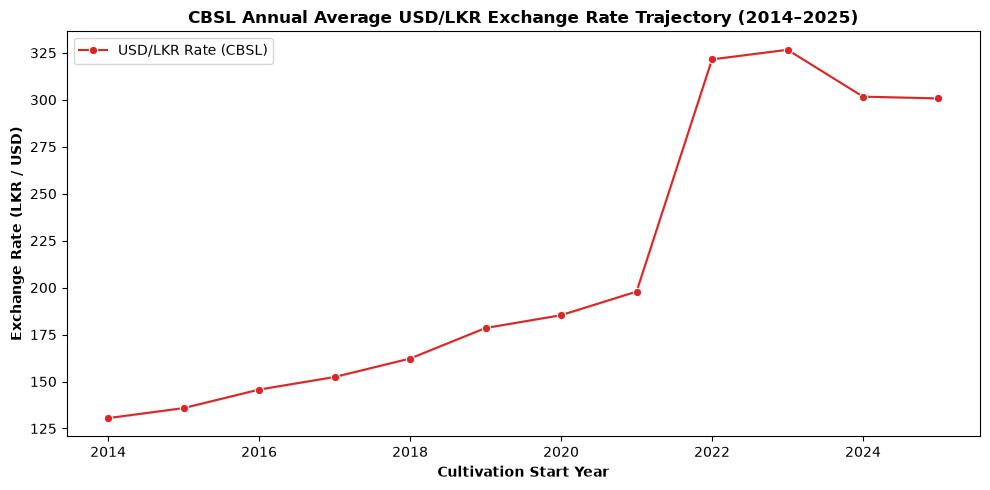

In [2]:
plt.figure(figsize=(10, 5))
sns.lineplot(data=df, x="Year_Start", y="USD_LKR_Rate", marker="o", color="#dc2626", label="USD/LKR Rate (CBSL)")
plt.title("CBSL Annual Average USD/LKR Exchange Rate Trajectory (2014–2025)", fontweight="bold")
plt.xlabel("Cultivation Start Year", fontweight="bold")
plt.ylabel("Exchange Rate (LKR / USD)", fontweight="bold")
plt.tight_layout()
plt.show()


### 2. Nominal Cost Surge by Crop
Examining how nominal cultivation expenditure evolved across the top agricultural crops.


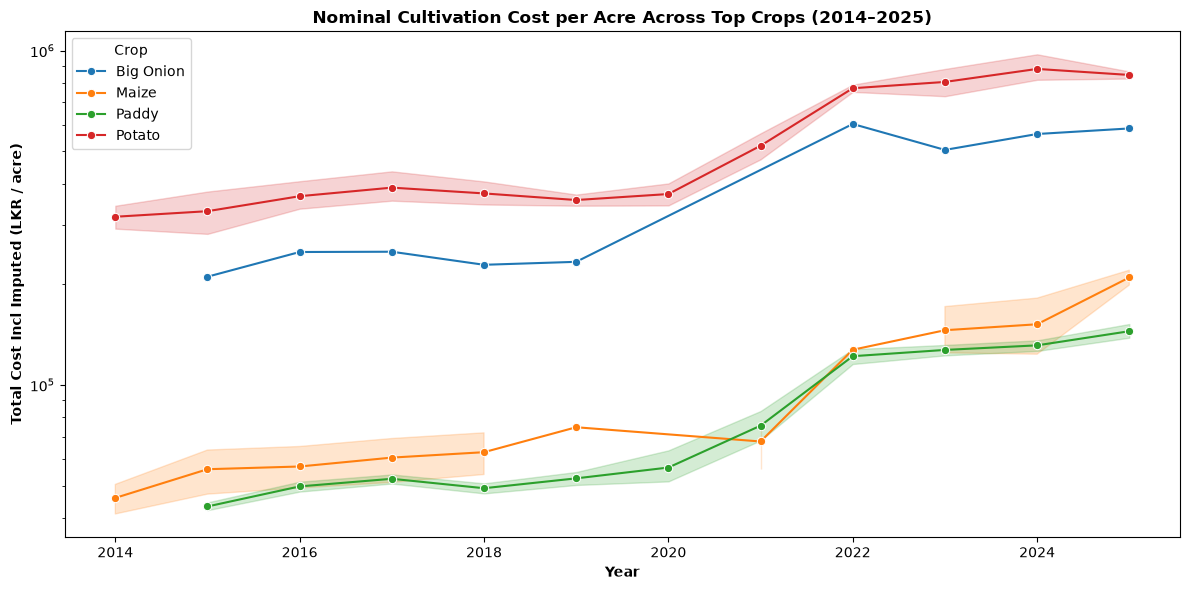

In [3]:
top_5 = ["Paddy", "Big Onion", "Potato", "Chilli", "Maize"]
plt.figure(figsize=(12, 6))
sns.lineplot(data=df[df["Crop"].isin(top_5)], x="Year_Start", y="Total_Cost_Incl_Imputed", hue="Crop", marker="o")
plt.title("Nominal Cultivation Cost per Acre Across Top Crops (2014–2025)", fontweight="bold")
plt.xlabel("Year", fontweight="bold")
plt.ylabel("Total Cost Incl Imputed (LKR / acre)", fontweight="bold")
plt.yscale("log")
plt.tight_layout()
plt.show()
